# Laboratorium 6. Przygotowanie danych dla Char-RNN

In [1]:
import hashlib
import json
import math
import platform
import re
import unicodedata
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 0
BATCH_SIZE = 32
STRIDE = 1
SEKW = 40
WINDOWS = (40, 80, 160)
ROOT = Path("dane_char_rnn")
ROOT.mkdir(exist_ok=True)
torch.manual_seed(SEED)
np.random.seed(SEED)
print("Python", platform.python_version(), "| PyTorch", torch.__version__,
      "| NumPy", np.__version__)
print("Kontrole danych na CPU | ziarno", SEED, "| batch", BATCH_SIZE,
      "| krok", STRIDE, "| SEKW", SEKW)

Python 3.12.14 | PyTorch 2.15.0+cpu | NumPy 2.5.5
Kontrole danych na CPU | ziarno 0 | batch 32 | krok 1 | SEKW 40


## 1. Źródło i warunki użycia

[Strona książki](https://wolnelektury.pl/katalog/lektura/lalka-tom-pierwszy/)
[Plik TXT](https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt)
[Zasady wykorzystania](https://wolnelektury.pl/info/zasady-wykorzystania/)
[Licencja Wolnej Sztuki 1.3](https://artlibre.org/licence/lal/pl/)

Sprawdzono też dwa gotowe zbiory z Hugging Face. [PleIAs/Polish-PD](https://huggingface.co/datasets/PleIAs/Polish-PD/blob/main/README.md) [SlayerLab/polish-dynaword, część Wolne Lektury](https://huggingface.co/datasets/SlayerLab/polish-dynaword/blob/main/data/wolne_lektury/wolne_lektury.md) podaje licencję osobno dla dokumentów. Wybrano bezpośredni TXT z ćwiczenia jeden spójny tekst o łatwych do zachowania granicach i pochodzeniu.

In [2]:
SOURCE_URL = "https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt"
EXPECTED_SOURCE_SHA256 = "84bc1adcb42e21e8ade9632a181b97fa50112be2b5e24044cf068cba464c6d2f"
source_path = Path("lalka_tom1_zrodlo.txt")
if source_path.exists():
    raw_bytes = source_path.read_bytes()
else:
    raw_bytes = urllib.request.urlopen(SOURCE_URL, timeout=30).read()
actual_hash = hashlib.sha256(raw_bytes).hexdigest()
if actual_hash != EXPECTED_SOURCE_SHA256:
    raise ValueError("Źródło różni się od użytej wersji. Użyj pliku TXT z pakietu.")
(ROOT / "lalka_tom1_zrodlo.txt").write_bytes(raw_bytes)
raw = raw_bytes.decode("utf-8", errors="strict")
assert "�" not in raw
print("Znaki w surowym pliku:", len(raw))
print("Bajty UTF-8:", len(raw_bytes), "| SHA-256:", actual_hash)

Znaki w surowym pliku: 784082
Bajty UTF-8: 860296 | SHA-256: 84bc1adcb42e21e8ade9632a181b97fa50112be2b5e24044cf068cba464c6d2f


## 2. Czyszczenie i podział przed tworzeniem okien
Usuwamy wstęp bibliograficzny przed rozdziałem I i stopkę serwisu zaczynającą się od oddzielacza. Pozostawiamy nagłówki rozdziałów, interpunkcję, wielkość liter oraz polskie znaki. Zamieniamy CRLF/CR na LF, stosujemy NFC, usuwamy BOM, zamieniamy NBSP na spację, usuwamy końcowe spacje w wierszach i ograniczamy dłuższe serie nowych linii do dwóch.

Proporcje docelowe wynoszą 80% / 10% / 10%. Przy jednym długim tekście wycinamy rozłączne, ciągłe części. Dwie granice wybieramy przy końcu akapitu najbliższym 80% i 90% długości. Dzięki temu początek akapitu nie jest odcinany. Wszystkie długości okien korzystają z tych samych części. Indeksy granic są zerowe i prawostronnie otwarte.

In [3]:
text = raw.replace("\r\n", "\n").replace("\r", "\n")
start = text.index("I. Jak wygląda")
end = text.index("\n-----\nTa lektura")
text = unicodedata.normalize("NFC", text[start:end])
text = text.replace("\ufeff", "").replace("\u00a0", " ")
text = "\n".join(line.rstrip() for line in text.splitlines())
text = re.sub(r"\n{3,}", "\n\n", text).strip() + "\n"
assert all(c in text for c in "ąćęłńóśźż")
assert not re.search(r"<[^>]+>", text)
assert "Ta lektura, podobnie jak" not in text
assert "\r" not in text and "\ufffd" not in text
clean_sha = hashlib.sha256(text.encode("utf-8")).hexdigest()
cuts = [m.end() for m in re.finditer("\n\n", text)]
boundaries = [0] + [
    min(cuts, key=lambda cut: abs(cut - int(len(text) * ratio)))
    for ratio in (0.8, 0.9)
] + [len(text)]
names = ("trening", "walidacja", "test")
parts = {
    name: text[a:b]
    for name, a, b in zip(names, boundaries, boundaries[1:])
}
assert 0 < boundaries[1] < boundaries[2] < len(text)
assert "".join(parts.values()) == text
assert all(len(part) > max(WINDOWS) for part in parts.values())
print("Po czyszczeniu:", len(text), "znaków | SHA-256:", clean_sha)
print("Granice:", boundaries)
print("Fragment po czyszczeniu:", repr(text[:300]))
for name, part in parts.items():
    print(name, len(part), f"{100*len(part)/len(text):.4f}%",
          "| różnych znaków", len(set(part)))
(ROOT / "korpus_oczyszczony.txt").write_text(text, encoding="utf-8")

Po czyszczeniu: 772580 znaków | SHA-256: 78401be670286a3acbaead8b51029522bfc63f3b0e1fb67679b91e977cb59cdc
Granice: [0, 618098, 695298, 772580]
Fragment po czyszczeniu: 'I. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\n\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorą'
trening 618098 80.0044% | różnych znaków 101
walidacja 77200 9.9925% | różnych znaków 74
test 77282 10.0031% | różnych znaków 81


## 3. Słownik wyłącznie z treningu
ID 0 jest zarezerwowane na [UNK]. Pozostałe ID pochodzą z posortowanych unikalnych znaków treningowych. Nowe znaki z walidacji lub testu otrzymałyby ID 0, a dekoder pokazałby dosłowny napis [UNK]. Zachowujemy słownik na kolejne etapy. Osobno raportujemy rozmiar alfabetu i rozmiar słownika z tokenem specjalnym.

In [4]:
alphabet = sorted(set(parts["trening"]))
itos = ["[UNK]"] + alphabet
stoi = {char: i + 1 for i, char in enumerate(alphabet)}
V = len(itos)

def encode(fragment):
    return np.array([stoi.get(c, 0) for c in fragment], dtype=np.int64)


def decode(ids):
    return "".join(itos[int(i)] for i in ids)


probe = parts["trening"][:150]
assert decode(encode(probe)) == probe
assert encode("🙂").tolist() == [0]
assert decode([0]) == "[UNK]"
arrays, unknowns = {}, {}
for name, part in parts.items():
    arrays[name] = encode(part)
    extra = Counter(c for c in part if c not in stoi)
    unknowns[name] = dict(extra)
    assert int((arrays[name] == 0).sum()) == sum(extra.values())
    if not extra:
        assert decode(arrays[name]) == part
    print(name, "| nieznane znaki:", dict(extra), "| wystąpienia:", sum(extra.values()))
print("Alfabet treningowy:", len(alphabet), "| słownik z [UNK]:", V)
print("Próba kodowania:", repr(probe))
print("Odtworzono dokładnie:", decode(encode(probe)) == probe)
print("Test sztucznego OOV: 🙂 →", encode("🙂").tolist(), "→", decode([0]))

trening | nieznane znaki: {} | wystąpienia: 0
walidacja | nieznane znaki: {} | wystąpienia: 0
test | nieznane znaki: {} | wystąpienia: 0
Alfabet treningowy: 101 | słownik z [UNK]: 102
Próba kodowania: 'I. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek?\n\nW początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim,'
Odtworzono dokładnie: True
Test sztucznego OOV: 🙂 → [0] → [UNK]


## 4. Dataset, DataLoader i kontrola par
Przy długości fragmentu N, oknie S i kroku K liczba par to max(0, floor((N − S − 1) / K) + 1). Dla K = 1 daje to max(0, N − S). Para wymaga S + 1 znaków. Osobny Dataset dla każdej części uniemożliwia przekroczenie granic podziału.

Trening ma shuffle=True, a walidacja i test shuffle=False. Wszędzie batch_size=32, drop_last=False, num_workers=0. Ostatni batch może być krótszy. Pary są wycinane podczas odczytu, więc nie przechowujemy pełnej macierzy zachodzących na siebie okien.

In [5]:
class DatasetZnakowy(Dataset):
    def __init__(self, data, sekw, stride=1):
        if sekw < 1 or stride < 1:
            raise ValueError("Długość okna i krok muszą być dodatnie.")
        self.data = torch.as_tensor(data, dtype=torch.long)
        self.sekw = sekw
        self.stride = stride

    def __len__(self):
        return max(0, (len(self.data) - self.sekw - 1) // self.stride + 1)

    def __getitem__(self, index):
        if index < 0 or index >= len(self):
            raise IndexError(index)
        start = index * self.stride
        return (self.data[start:start + self.sekw],
                self.data[start + 1:start + self.sekw + 1])


datasets = {name: DatasetZnakowy(a, SEKW, STRIDE) for name, a in arrays.items()}
loaders = {
    name: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=name == "trening",
                     drop_last=False, num_workers=0,
                     generator=torch.Generator().manual_seed(SEED))
    for name, ds in datasets.items()
}
checks = {}
for name, ds in datasets.items():
    xb, yb = next(iter(loaders[name]))
    assert xb.shape == yb.shape == (BATCH_SIZE, SEKW)
    assert xb.dtype == yb.dtype == torch.int64
    assert 0 <= int(xb.min()) <= int(xb.max()) < V
    assert 0 <= int(yb.min()) <= int(yb.max()) < V
    assert torch.equal(xb[:, 1:], yb[:, :-1])
    batch_pair = torch.cat((xb[0], yb[0, -1:]))
    decoded_batch_pair = decode(batch_pair)
    batch_start = parts[name].find(decoded_batch_pair)
    assert batch_start >= 0
    assert parts[name][batch_start:batch_start+SEKW+1] == decoded_batch_pair
    x, y = ds[0]
    assert torch.equal(x, torch.from_numpy(arrays[name][:SEKW]))
    assert torch.equal(y, torch.from_numpy(arrays[name][1:SEKW+1]))
    source = parts[name][:SEKW+1]
    assert decode(x) == source[:-1] and decode(y) == source[1:]
    last_start = (len(ds) - 1) * STRIDE
    last_x, last_y = ds[len(ds) - 1]
    assert last_start + SEKW < len(arrays[name])
    assert torch.equal(last_y, torch.from_numpy(
        arrays[name][last_start+1:last_start+SEKW+1]))
    checks[name] = {
        "shape": list(xb.shape), "x_min": int(xb.min()), "x_max": int(xb.max()),
        "y_min": int(yb.min()), "y_max": int(yb.max()),
        "source": source, "input": decode(x), "target": decode(y),
    }
    print(name, "| X", tuple(xb.shape), "| Y", tuple(yb.shape), "| int64")
    print("Zakres X:", checks[name]["x_min"], checks[name]["x_max"],
          "| zakres Y:", checks[name]["y_min"], checks[name]["y_max"])
    print("Źródło (pierwsze 41 znaków):", repr(source))
    print("X:", repr(decode(x)))
    print("Y:", repr(decode(y)))
    print("Zgodność ze źródłem i przesunięcie o jeden znak: OK")
assert len(DatasetZnakowy(np.arange(40), 40)) == 0
assert len(DatasetZnakowy(np.arange(41), 40)) == 1

trening | X (32, 40) | Y (32, 40) | int64
Zakres X: 1 101 | zakres Y: 1 101
Źródło (pierwsze 41 znaków): 'I. Jak wygląda firma J. Mincel i S. Wokul'
X: 'I. Jak wygląda firma J. Mincel i S. Woku'
Y: '. Jak wygląda firma J. Mincel i S. Wokul'
Zgodność ze źródłem i przesunięcie o jeden znak: OK
walidacja | X (32, 40) | Y (32, 40) | int64
Zakres X: 2 98 | zakres Y: 2 98
Źródło (pierwsze 41 znaków): '— Nic o tym nie wiem — odpowiedział Szlan'
X: '— Nic o tym nie wiem — odpowiedział Szla'
Y: ' Nic o tym nie wiem — odpowiedział Szlan'
Zgodność ze źródłem i przesunięcie o jeden znak: OK
test | X (32, 40) | Y (32, 40) | int64
Zakres X: 2 96 | zakres Y: 2 96
Źródło (pierwsze 41 znaków): 'Przez całą noc śnił się pannie Izabeli St'
X: 'Przez całą noc śnił się pannie Izabeli S'
Y: 'rzez całą noc śnił się pannie Izabeli St'
Zgodność ze źródłem i przesunięcie o jeden znak: OK


## 5. Wpływ długości okna i częstości znaków
Wszystkie porównania korzystają z tego samego tekstu i kroku 1. Liczby batchy uwzględniają ostatni, niepełny batch.

SEKW | zbiór | znaki | udział % | różne znaki | pary | batche
  40 | trening   | 618098 | 80.0044 | 101 | 618058 | 19315
  40 | walidacja |  77200 | 9.9925 |  74 |  77160 |  2412
  40 | test      |  77282 | 10.0031 |  81 |  77242 |  2414
  80 | trening   | 618098 | 80.0044 | 101 | 618018 | 19314
  80 | walidacja |  77200 | 9.9925 |  74 |  77120 |  2410
  80 | test      |  77282 | 10.0031 |  81 |  77202 |  2413
 160 | trening   | 618098 | 80.0044 | 101 | 617938 | 19311
 160 | walidacja |  77200 | 9.9925 |  74 |  77040 |  2408
 160 | test      |  77282 | 10.0031 |  81 |  77122 |  2411
Najczęstsze znaki: [("' '", 93889, 15.19), ("'a'", 44131, 7.14), ("'i'", 42211, 6.829), ("'e'", 37054, 5.995), ("'o'", 34044, 5.508), ("'z'", 27753, 4.49), ("'n'", 24709, 3.998), ("'s'", 20501, 3.317), ("'r'", 19290, 3.121), ("'y'", 18477, 2.989), ("'c'", 18331, 2.966), ("'w'", 17755, 2.873), ("'k'", 16789, 2.716), ("'t'", 16102, 2.605), ("'d'", 15481, 2.505)]


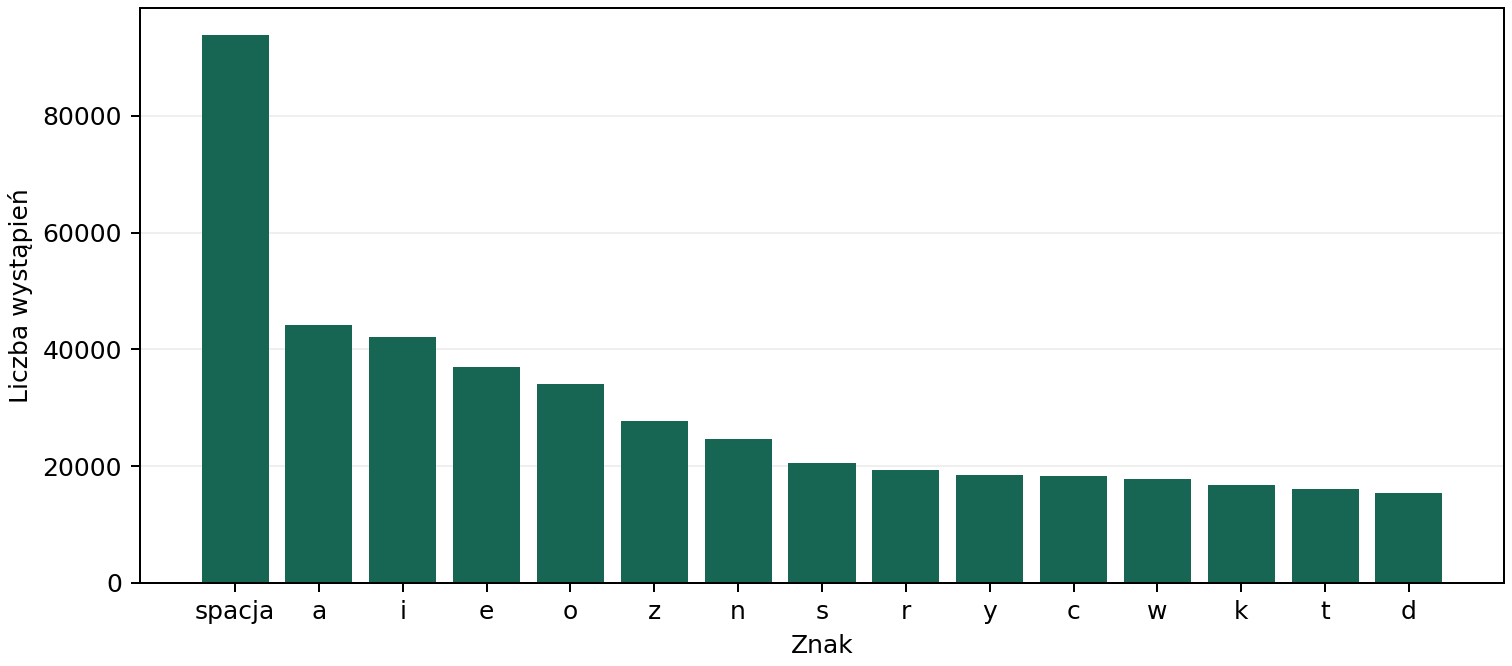

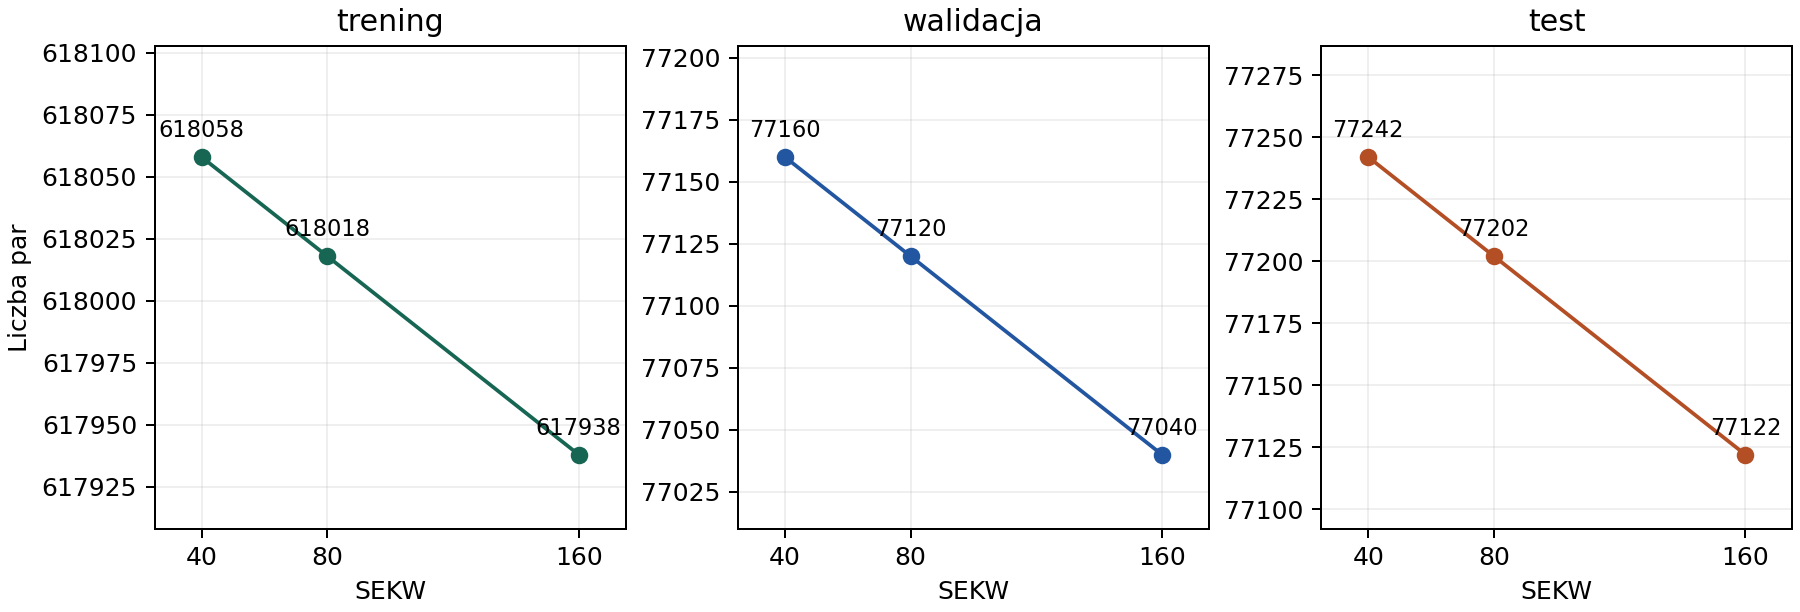

In [6]:
table = []
print("SEKW | zbiór | znaki | udział % | różne znaki | pary | batche")
for sekw in WINDOWS:
    for name in names:
        count = len(DatasetZnakowy(arrays[name], sekw, STRIDE))
        row = {
            "sekw": sekw, "name": name, "chars": len(parts[name]),
            "share": len(parts[name]) / len(text) * 100,
            "unique": len(set(parts[name])), "pairs": count,
            "batches": math.ceil(count / BATCH_SIZE),
        }
        table.append(row)
        print(f"{sekw:4} | {name:9} | {row['chars']:6} | {row['share']:.4f} | "
              f"{row['unique']:3} | {count:6} | {row['batches']:5}")
freq = Counter(parts["trening"])
top = freq.most_common(15)
labels = ["spacja" if c == " " else "LF" if c == "\n" else c for c, _ in top]
fig, ax = plt.subplots(figsize=(8.4, 3.7), layout="constrained")
ax.bar(labels, [n for _, n in top], color="#176653")
ax.set(xlabel="Znak", ylabel="Liczba wystąpień")
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
fig.savefig(ROOT / "czestosc_znakow.png", dpi=180)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), layout="constrained")
for ax, name, color in zip(axes, names, ["#176653", "#2356a0", "#b34e25"]):
    series = [r for r in table if r["name"] == name]
    values = [r["pairs"] for r in series]
    ax.plot(WINDOWS, values, color=color, marker="o")
    for window, count in zip(WINDOWS, values):
        ax.annotate(str(count), (window, count), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=9)
    ax.set(title=name, xlabel="SEKW", xticks=WINDOWS,
           ylim=(min(values)-30, max(values)+45), xlim=(25, 175))
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    ax.grid(alpha=.2)
axes[0].set_ylabel("Liczba par")
fig.savefig(ROOT / "liczba_par.png", dpi=180)
plt.show()
print("Najczęstsze znaki:", [(repr(c), n, round(100*n/len(parts['trening']), 3)) for c,n in top])

## 6. Zapis danych na laboratorium 7
Zapis obejmuje tekst, słownik, tablice int64 i manifest z granicami oraz sumami SHA-256.

In [7]:
manifest = {
    "source_url": SOURCE_URL, "source_sha256": actual_hash,
    "clean_sha256": clean_sha, "seed": SEED, "stride": STRIDE,
    "batch_size": BATCH_SIZE, "default_sekw": SEKW,
    "windows": list(WINDOWS), "drop_last": False,
    "alphabet_size": len(alphabet), "vocab_size": V,
    "torch_version": torch.__version__,
    "indexing": "zero-based, half-open [start, stop)",
    "splits": {},
}
for name, a, b in zip(names, boundaries, boundaries[1:]):
    (ROOT / f"{name}.txt").write_text(parts[name], encoding="utf-8")
    np.save(ROOT / f"{name}.npy", arrays[name], allow_pickle=False)
    manifest["splits"][name] = {
        "start": a, "stop": b, "chars": b-a,
        "sha256": hashlib.sha256(parts[name].encode("utf-8")).hexdigest(),
        "array_sha256": hashlib.sha256((ROOT/f"{name}.npy").read_bytes()).hexdigest(),
        "unknown_counts": unknowns[name],
    }
(ROOT / "slownik.json").write_text(json.dumps(
    {"stoi": stoi, "itos": itos, "unk_id": 0}, ensure_ascii=False, indent=2), encoding="utf-8")
(ROOT / "podzial.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
results = {"manifest": manifest, "table": table, "checks": checks,
           "frequency": [[c,n] for c,n in top], "preview": text[:300],
           "raw_chars": len(raw), "clean_chars": len(text)}
(ROOT / "wyniki.json").write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
saved_vocab = json.loads((ROOT / "slownik.json").read_text(encoding="utf-8"))
assert saved_vocab["itos"] == itos and saved_vocab["stoi"] == stoi
for name in names:
    restored = np.load(ROOT / f"{name}.npy", allow_pickle=False)
    np.testing.assert_array_equal(restored, arrays[name])
print("Zapis i ponowny odczyt słownika, podziału i tablic: OK")
print("Pliki:", ", ".join(p.name for p in sorted(ROOT.iterdir())))

Zapis i ponowny odczyt słownika, podziału i tablic: OK
Pliki: czestosc_znakow.png, korpus_oczyszczony.txt, lalka_tom1_zrodlo.txt, liczba_par.png, podzial.json, slownik.json, test.npy, test.txt, trening.npy, trening.txt, walidacja.npy, walidacja.txt, wyniki.json
